02. Matched Parent Series and Leakage-Safe Split
Questions:
1. How rich are the fixed-side-chain matched series?
2. How strongly do large sources such as 2020_Townsend influence the dataset?
3. Did the train/validation/test split keep the same global side-chain scaffold in only one split?
The split used by PepGate is scaffold-level: the global sidechain_signature, not publication identity, is the split unit.

In [7]:
from pathlib import Path
import sys
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "analysis").exists():
            return candidate
    raise RuntimeError(
        "Could not find the PepGate repository root. "
        "Open this notebook from inside the PepGate repository."
    )

ROOT = find_repo_root()
SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"
DATA = ROOT / "data"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PepGate root:", ROOT)

PepGate root: /Users/yeritmaryrodriguezdelgado/Desktop/PEPGATE_YRD


In [8]:
MATCHED = OUTPUTS / "matched_parent_series.csv"
PARENT_SPLIT = OUTPUTS / "parent_split.csv"
PEPTIDES_SPLIT = OUTPUTS / "peptides_with_split.csv"

for path in [MATCHED, PARENT_SPLIT, PEPTIDES_SPLIT]:
    assert path.exists(), (
        f"Missing {path}. Run the matched-series and parent-split analysis scripts first."
    )

matched = pd.read_csv(MATCHED, low_memory=False)
parent_split = pd.read_csv(PARENT_SPLIT, low_memory=False)
peptides_split = pd.read_csv(PEPTIDES_SPLIT, low_memory=False)

display(matched.head())

,Source,sidechain_signature,n_peptides,n_patterns,ring_size
0,2006_Rezai_1,"('Abu', 'Sar', 'Leu', 'Val', 'Leu', 'Ala', 'Al...",1,1,11
1,2006_Rezai_1,"('Leu', 'Leu', 'Leu', 'Leu', 'Pro', 'Tyr')",9,9,6
2,2006_Rezai_2,"('Leu', 'Leu', 'Leu', 'Leu', 'Leu', 'Tyr(Me)',...",1,1,7
3,2006_Rezai_2,"('Leu', 'Leu', 'Leu', 'Leu', 'Tyr(Me)', 'Pro')",5,5,6
4,2006_Rezai_2,"('Leu', 'Leu', 'Leu', 'Tyr(Me)', 'Pro', 'Leu',...",1,1,7


1. Distribution of backbone-pattern richness

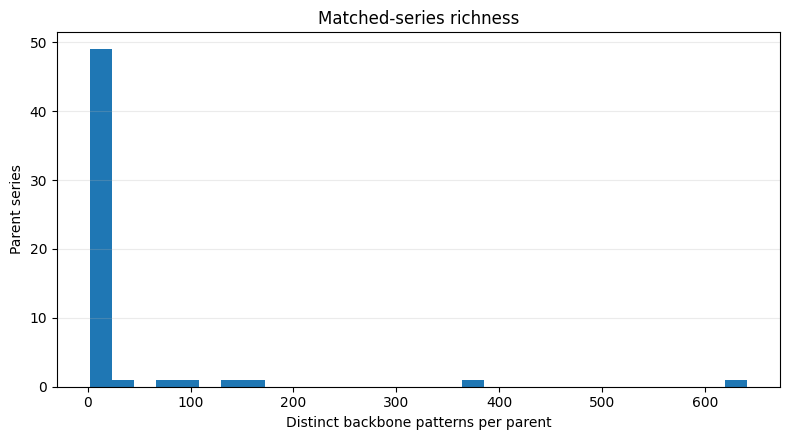

Median patterns per matched parent: 2.0
Maximum patterns in one parent: 641


In [9]:
matched_multi = matched[matched["n_patterns"] >= 2].copy()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(matched_multi["n_patterns"], bins=30)
ax.set_xlabel("Distinct backbone patterns per parent")
ax.set_ylabel("Parent series")
ax.set_title("Matched-series richness")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Median patterns per matched parent:", matched_multi["n_patterns"].median())
print("Maximum patterns in one parent:", matched_multi["n_patterns"].max())

2. Largest matched parent series
Large combinatorial libraries are useful for evaluating search, but they can dominate peptide-level statistics. This is why later benchmarking averages over parents, not individual peptides.

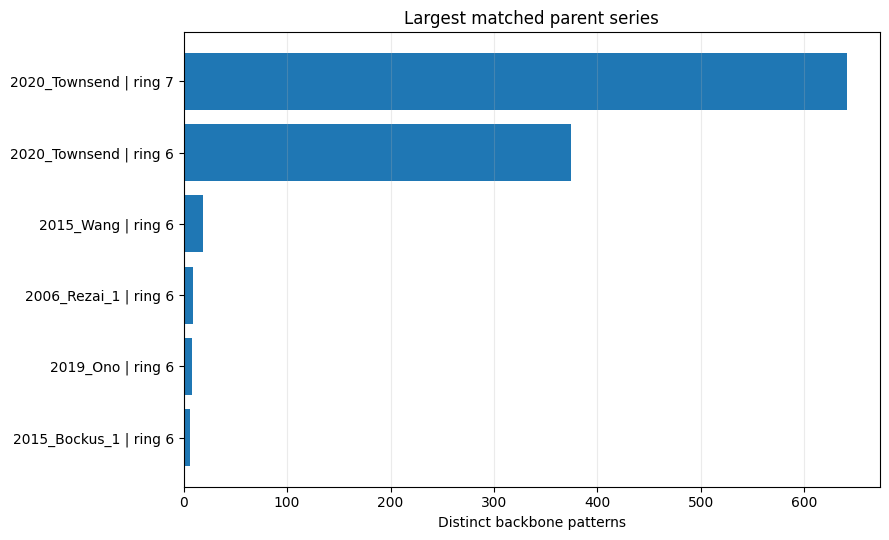

,Source,ring_size,n_peptides,n_patterns
249,2020_Townsend,7,641,641
248,2020_Townsend,6,374,374
252,2020_Townsend,7,166,166
251,2020_Townsend,7,137,137
253,2020_Townsend,6,88,88
250,2020_Townsend,6,79,79
254,2020_Townsend,7,42,42
255,2020_Townsend,6,22,22
144,2015_Wang,6,19,19
1,2006_Rezai_1,6,9,9


In [10]:
top = matched_multi.nlargest(12, "n_patterns").copy()
top["label"] = top["Source"].astype(str) + " | ring " + top["ring_size"].astype(str)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = top.sort_values("n_patterns")
ax.barh(plot_df["label"], plot_df["n_patterns"])
ax.set_xlabel("Distinct backbone patterns")
ax.set_title("Largest matched parent series")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(top[["Source", "ring_size", "n_peptides", "n_patterns"]])

3. Source contribution

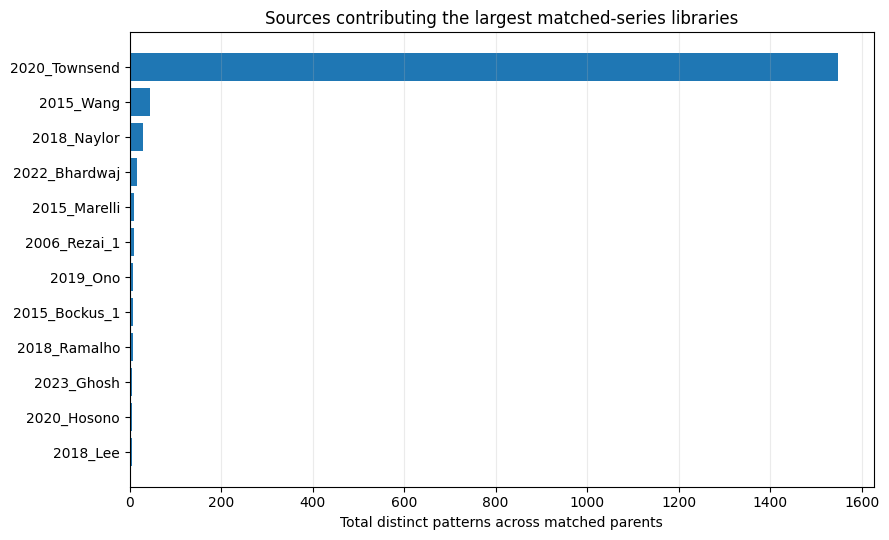

,Source,matched_parents,total_patterns
12,2020_Townsend,8,1549
6,2015_Wang,8,44
8,2018_Naylor,15,30
13,2022_Bhardwaj,8,16
5,2015_Marelli,3,10
0,2006_Rezai_1,1,9
3,2015_Bockus_1,2,8
10,2019_Ono,1,8
9,2018_Ramalho,3,7
7,2018_Lee,1,6


In [11]:
source_patterns = (
    matched_multi.groupby("Source", as_index=False)
    .agg(
        matched_parents=("sidechain_signature", "count"),
        total_patterns=("n_patterns", "sum"),
    )
    .sort_values("total_patterns", ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = source_patterns.sort_values("total_patterns")
ax.barh(plot_df["Source"], plot_df["total_patterns"])
ax.set_xlabel("Total distinct patterns across matched parents")
ax.set_title("Sources contributing the largest matched-series libraries")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(source_patterns)

4. Ring-size concentration among matched parents

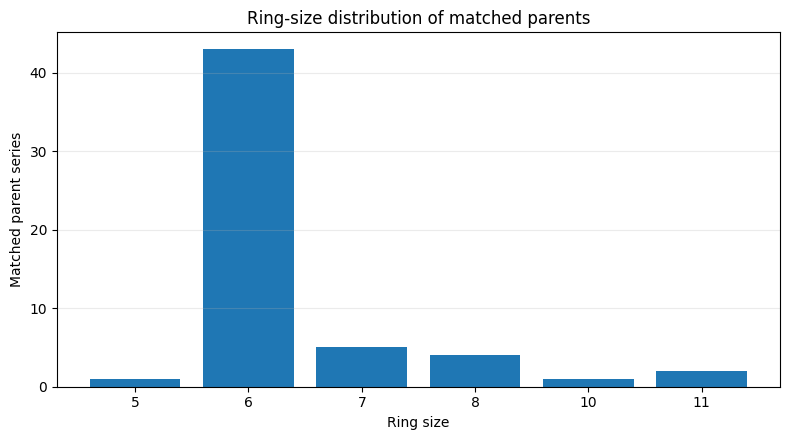

In [12]:
ring_parent_counts = (
    matched_multi["ring_size"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ring_parent_counts.index.astype(str), ring_parent_counts.values)
ax.set_xlabel("Ring size")
ax.set_ylabel("Matched parent series")
ax.set_title("Ring-size distribution of matched parents")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

5. Train / validation / test split
parent_split.csv was built from global side-chain signatures. If the same scaffold appears in two papers, it must still remain in a single split.

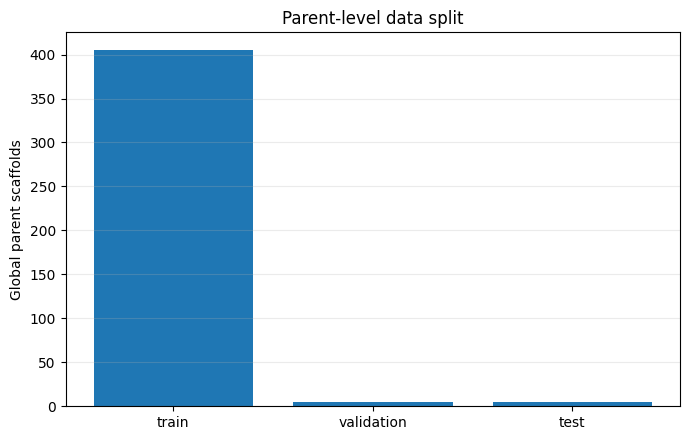

,parents
split,
train,405
validation,5
test,5


In [13]:
split_counts = (
    parent_split["split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .dropna()
)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(split_counts.index, split_counts.values)
ax.set_ylabel("Global parent scaffolds")
ax.set_title("Parent-level data split")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(split_counts.rename("parents").to_frame())

6. Evaluation-eligible parents and Townsend balance

has_townsend,non_Townsend,Townsend
split,,
test,3,2
train,8,4
validation,3,2


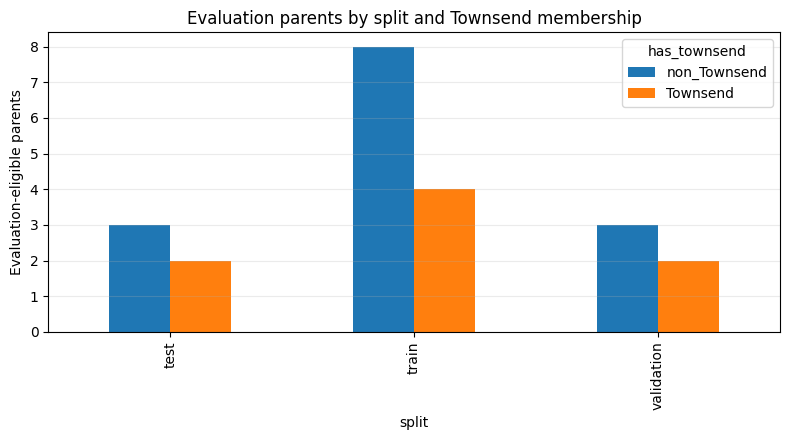

In [14]:
eval_df = parent_split[parent_split["evaluation_eligible"] == True].copy()

eval_table = pd.crosstab(
    eval_df["split"],
    eval_df["has_townsend"],
).rename(columns={False: "non_Townsend", True: "Townsend"})

display(eval_table)

ax = eval_table.plot(kind="bar", figsize=(8, 4.5))
ax.set_ylabel("Evaluation-eligible parents")
ax.set_title("Evaluation parents by split and Townsend membership")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

7. Verify zero scaffold leakage

In [15]:
signature_splits = (
    parent_split.groupby("sidechain_signature")["split"]
    .nunique()
)

leaking = signature_splits[signature_splits > 1]

print("Scaffolds appearing in more than one split:", len(leaking))
assert len(leaking) == 0, "Leakage detected!"
print("✓ No global side-chain scaffold leakage detected.")

Scaffolds appearing in more than one split: 0
✓ No global side-chain scaffold leakage detected.


Takeaway
The split is intentionally conservative: side-chain identity is treated as the independent parent unit across publications. This prevents the same scaffold from appearing in both training and held-out evaluation.